# Insurer or Plan? Analysis for the JSM 2027 Student Paper Competition draft
Ankit Bisht · Harrisburg University of Science and Technology

Reproduces every table and figure in the draft paper. Data: CMS Transparency in Coverage Public Use Files, individual-market medical plans, plan-year files 2024, 2025 and 2026 (claims for calendar years 2022, 2023 and 2024). Files are downloaded from CMS on first run and cached in `data/`. Figures are written to `figures/`. Seed: 42.

In [1]:
import io, zipfile, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error

warnings.simplefilter("ignore")      # statsmodels boundary notices; variance components are checked explicitly below
SEED = 42
DATA, FIG = Path("data"), Path("figures")
DATA.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
REC, DEN = "Plan_Number_Claims_Received_In_Network", "Plan_Number_Claims_Denied_In_Network"

def load_puf(file_year):
    """Individual-market QHP sheet of the CMS PUF; the file for plan year Y reports claims for calendar year Y - 2."""
    local = DATA / f"transparency_in_coverage_puf_{file_year}.xlsx"
    if not local.exists():
        url = f"https://download.cms.gov/marketplace-puf/{file_year}/transparency-in-coverage-puf.zip"
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
        local.write_bytes(z.read([n for n in z.namelist() if n.lower().endswith(".xlsx")][0]))
    return pd.read_excel(local, sheet_name=f"Transparency {file_year} - Ind QHP", header=2, keep_default_na=False)

raw, use = {}, {}
for fy in (2024, 2025, 2026):
    cy = fy - 2
    r = load_puf(fy)
    for c in (REC, DEN):
        r[c + "_num"] = pd.to_numeric(r[c], errors="coerce")
    raw[cy] = r
    u = r[(r[REC + "_num"] > 0) & r[DEN + "_num"].notna()].copy()
    u["rate"] = u[DEN + "_num"] / u[REC + "_num"]
    u["iss"] = u["Issuer_ID"].astype(str)
    use[cy] = u.reset_index(drop=True)
print({cy: r.shape for cy, r in raw.items()})

{2022: (5050, 45), 2023: (4541, 46), 2024: (4159, 46)}


## Table 1. Fitness for use of the public file

In [2]:
rows = []
for cy, r in raw.items():
    u = use[cy]
    rows.append({"claims year": cy, "plans in file": len(r), "coded N/A (new plan or insurer)": int((r[REC] == "N/A").sum()),
                 "suppressed (**)": int(((r[REC] == "**") | (r[DEN] == "**")).sum()),
                 "usable plans": len(u), "usable share": len(u) / len(r),
                 "insurers": u["iss"].nunique(), "states": u["State"].nunique(),
                 "claims received (millions)": u[REC + "_num"].sum() / 1e6,
                 "overall denial rate": u[DEN + "_num"].sum() / u[REC + "_num"].sum(),
                 "median plan rate": u["rate"].median()})
table1 = pd.DataFrame(rows).set_index("claims year")
print(table1.round(3).T.to_string())

u = use[2024]
enr = pd.to_numeric(u["Average Monthly Enrollment"], errors="coerce")
print()
print("2024: enrollment missing or suppressed among usable plans:", round(enr.isna().mean(), 3))
print("2024: median claims received per average monthly enrollee:", round((u.loc[enr > 0, REC + "_num"] / enr[enr > 0]).median()))
reason_cols = [c for c in raw[2024].columns if c.startswith("Plan_Number_Claims_Denied_") and "Network" not in c and not c.endswith("_num")]
reasons = pd.Series({c.replace("Plan_Number_Claims_Denied_", ""): pd.to_numeric(raw[2024][c], errors="coerce").sum() for c in reason_cols})
print("2024: denials summed over reason columns:", f"{reasons.sum():,.0f}", "| in-network denials:", f"{u[DEN + '_num'].sum():,.0f}",
      "| in- plus out-of-network:", f"{u[DEN + '_num'].sum() + pd.to_numeric(u['Plan_Number_Claims_Denied_Out_of_Network'], errors='coerce').sum():,.0f}")
print("2024: largest reason category:", reasons.idxmax(), f"({reasons.max() / reasons.sum():.3f} of reason total)")
excl = raw[2024][~raw[2024].index.isin(raw[2024][(raw[2024][REC + '_num'] > 0) & raw[2024][DEN + '_num'].notna()].index)]
print("2024: HMO share, excluded vs usable:", round((excl["Plan_Type"] == "HMO").mean(), 3), "vs", round((u["Plan_Type"] == "HMO").mean(), 3))
print("2024: largest insurer's share of usable plans:", round(u["iss"].value_counts(normalize=True).iloc[0], 3))

claims year                          2022      2023      2024
plans in file                    5050.000  4541.000  4159.000
coded N/A (new plan or insurer)  3092.000  2060.000  1600.000
suppressed (**)                   200.000    45.000    21.000
usable plans                     1755.000  2406.000  2527.000
usable share                        0.348     0.530     0.608
insurers                          169.000   174.000   149.000
states                             32.000    31.000    30.000
claims received (millions)        245.282   294.475   344.345
overall denial rate                 0.162     0.190     0.190
median plan rate                    0.149     0.180     0.176

2024: enrollment missing or suppressed among usable plans: 0.231
2024: median claims received per average monthly enrollee: 453
2024: denials summed over reason columns: 78,605,749 | in-network denials: 65,578,278 | in- plus out-of-network: 75,856,033
2024: largest reason category: Other (0.358 of reason total)
2024

## Figure 1. Plan and insurer denial rates, 2024

Insurers with 5+ usable plans: 139; rate min 0.027, median 0.192, max 0.410


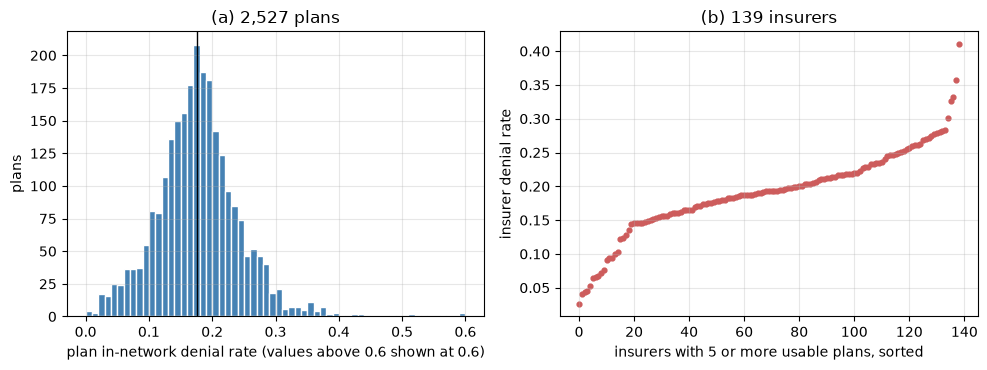

In [3]:
u = use[2024]
ins = u.groupby("iss").apply(lambda g: pd.Series({"plans": len(g), "rate": g[DEN + "_num"].sum() / g[REC + "_num"].sum()}), include_groups=False)
big = ins[ins["plans"] >= 5].sort_values("rate")
print(f"Insurers with 5+ usable plans: {len(big)}; rate min {big['rate'].min():.3f}, median {big['rate'].median():.3f}, max {big['rate'].max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(u["rate"].clip(upper=0.6), bins=60, color="steelblue", edgecolor="white")
ax[0].axvline(u["rate"].median(), color="black", lw=1)
ax[0].set_xlabel("plan in-network denial rate (values above 0.6 shown at 0.6)"); ax[0].set_ylabel("plans")
ax[0].set_title("(a) 2,527 plans")
ax[1].scatter(range(len(big)), big["rate"], s=12, color="indianred")
ax[1].set_xlabel("insurers with 5 or more usable plans, sorted"); ax[1].set_ylabel("insurer denial rate")
ax[1].set_title(f"(b) {len(big)} insurers")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "fig1_rates.png", dpi=200); plt.show()

## Table 2. Variance components

In [4]:
d = use[2024]
three = smf.mixedlm("rate ~ 1", d, groups=d["State"], re_formula="1", vc_formula={"iss": "0 + C(iss)"}).fit(reml=True)
vs, vi, ve = three.cov_re.iloc[0, 0], three.vcomp[0], three.scale
tot = vs + vi + ve
print(f"Three-level REML (converged={three.converged}): state {vs/tot:.3f}, insurer within state {vi/tot:.3f}, plan {ve/tot:.3f}")

two = smf.mixedlm("rate ~ 1", d, groups=d["iss"]).fit(reml=True)
v_ins, v_res = two.cov_re.iloc[0, 0], two.scale
print(f"Two-level REML: insurer ICC {v_ins/(v_ins+v_res):.3f}; insurer SD {np.sqrt(v_ins):.4f}; plan (residual) SD {np.sqrt(v_res):.4f}")

attrs = 'rate ~ C(Plan_Type, Treatment("HMO")) + C(Metal_Level, Treatment("Silver")) + C(Exchange_Type)'
ri = smf.mixedlm(attrs, d, groups=d["iss"]).fit(reml=True)
v_ins2 = ri.cov_re.iloc[0, 0]
print(f"After adding plan attributes: insurer ICC {v_ins2/(v_ins2+ri.scale):.3f}; share of insurer variance explained by plan attributes {1 - v_ins2/v_ins:.3f}")

# Cluster bootstrap over insurers for the ICC
rng = np.random.default_rng(SEED); insurers = d["iss"].unique(); boot = []
by = {s: g for s, g in d.groupby("iss")}
for b in range(200):
    pick = rng.choice(insurers, len(insurers), replace=True)
    bd = pd.concat([by[s].assign(bid=f"{s}_{j}") for j, s in enumerate(pick)])
    f = smf.mixedlm("rate ~ 1", bd, groups=bd["bid"]).fit(reml=True)
    boot.append(f.cov_re.iloc[0, 0] / (f.cov_re.iloc[0, 0] + f.scale))
print(f"Insurer ICC 95% cluster-bootstrap interval (200 resamples): {np.percentile(boot, 2.5):.3f} to {np.percentile(boot, 97.5):.3f}")

# Moment-based check: between-group share of variance (eta-squared) and the group-count correction (epsilon-squared)
def shares(y, g):
    y = np.asarray(y); g = pd.Series(g).astype(str).values
    sst = ((y - y.mean()) ** 2).sum(); m = pd.Series(y).groupby(g).transform("mean").values
    ssb = ((m - y.mean()) ** 2).sum(); k, n = len(set(g)), len(y)
    return ssb / sst, (ssb - (k - 1) * (sst - ssb) / (n - k)) / sst
for col in ["iss", "State", "Plan_Type", "Metal_Level"]:
    e, eps = shares(d["rate"], d[col])
    print(f"  {col:12s} eta^2 {e:.3f}  epsilon^2 {eps:.3f}")
within = d["rate"] - d.groupby("iss")["rate"].transform("mean")
frac_within = (within ** 2).sum() / ((d["rate"] - d["rate"].mean()) ** 2).sum()
for col in ["Plan_Type", "Metal_Level"]:
    e, _ = shares(within, d[col])
    print(f"  {col:12s} within insurer, share of total variance {e * frac_within:.3f}")

Three-level REML (converged=True): state 0.203, insurer within state 0.417, plan 0.379


Two-level REML: insurer ICC 0.612; insurer SD 0.0600; plan (residual) SD 0.0478


After adding plan attributes: insurer ICC 0.611; share of insurer variance explained by plan attributes 0.037


Insurer ICC 95% cluster-bootstrap interval (200 resamples): 0.446 to 0.736
  iss          eta^2 0.545  epsilon^2 0.517
  State        eta^2 0.239  epsilon^2 0.230
  Plan_Type    eta^2 0.060  epsilon^2 0.059
  Metal_Level  eta^2 0.003  epsilon^2 0.002
  Plan_Type    within insurer, share of total variance 0.006
  Metal_Level  within insurer, share of total variance 0.004


## Table 3. Plan-attribute effects with and without accounting for the insurer

In [5]:
ols = smf.ols(attrs, d).fit(cov_type="cluster", cov_kwds={"groups": d["iss"]})
fe = smf.ols('rate ~ C(Plan_Type, Treatment("HMO")) + C(Metal_Level, Treatment("Silver")) + C(iss)', d).fit(
    cov_type="cluster", cov_kwds={"groups": d["iss"]})
keys = [k for k in ols.params.index if "Plan_Type" in k or "Metal_Level" in k]
table3 = pd.DataFrame({
    "pooled OLS": ols.params[keys], "OLS cluster SE": ols.bse[keys],
    "random intercept": ri.fe_params[keys], "RI SE": ri.bse_fe[keys],
    "insurer fixed effects": fe.params[keys], "FE cluster SE": fe.bse[keys]})
table3.index = [k.split("[T.")[-1].rstrip("]") + (" vs HMO" if "Plan_Type" in k else " vs Silver") for k in keys]
print("Coefficients in denial-rate units (0.01 = one percentage point); reference: HMO, Silver")
table3.round(4)

Coefficients in denial-rate units (0.01 = one percentage point); reference: HMO, Silver


,pooled OLS,OLS cluster SE,random intercept,RI SE,insurer fixed effects,FE cluster SE
EPO vs HMO,0.0101,0.0112,-0.0153,0.0063,-0.0241,0.0174
POS vs HMO,-0.0349,0.0066,-0.0232,0.0036,-0.0242,0.0056
PPO vs HMO,-0.0282,0.0129,-0.0341,0.0064,-0.0378,0.0313
Bronze vs Silver,-0.0048,0.0061,-0.0021,0.0024,-0.0021,0.0064
Catastrophic vs Silver,-0.0008,0.0100,0.0138,0.0058,0.0140,0.0087
Gold vs Silver,-0.0075,0.0058,-0.0050,0.0024,-0.0048,0.0059
Platinum vs Silver,-0.0190,0.0161,-0.0239,0.0101,-0.0224,0.0079


## Table 4 and Figure 2. Predicting denial rates for insurers not seen in training (2024)

                                                  MAE random 5-fold  MAE grouped by insurer  SD grouped  grouped minus baseline
Baseline: training-fold mean                                 0.0495                  0.0506      0.0074                  0.0000
Ridge: plan attributes                                       0.0473                  0.0503      0.0078                 -0.0003
Ridge: plan attributes + state                               0.0473                  0.0522      0.0052                  0.0016
Ridge: plan attributes + prior-year insurer rate             0.0453                  0.0504      0.0069                 -0.0002
Gradient boosting: plan attributes + state                   0.0386                  0.0664      0.0122                  0.0158


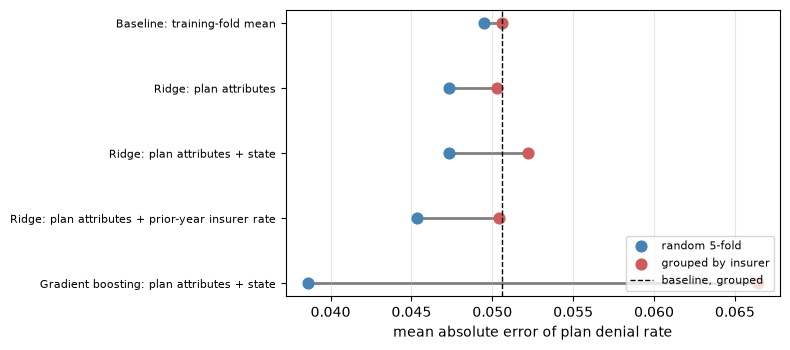

In [6]:
PLAN_CAT = ["Plan_Type", "Metal_Level", "Exchange_Type"]
d = use[2024].copy()
d["enrollment"] = pd.to_numeric(d["Average Monthly Enrollment"], errors="coerce")
p = use[2023].groupby("iss").apply(lambda g: g[DEN + "_num"].sum() / g[REC + "_num"].sum(), include_groups=False)
pr = raw[2023].drop_duplicates("Issuer_ID").copy()
for c in ("Issuer_Claims_Received_In_Network", "Issuer_Claims_Denied_In_Network"):
    pr[c] = pd.to_numeric(pr[c], errors="coerce")
pr = pr[pr["Issuer_Claims_Received_In_Network"] > 0]
prior = (pr["Issuer_Claims_Denied_In_Network"] / pr["Issuer_Claims_Received_In_Network"]).set_axis(pr["Issuer_ID"].astype(str))
d["prior_issuer_rate"] = d["iss"].map(prior)

log_enroll = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), FunctionTransformer(np.log1p), StandardScaler())
def design(cat, extra=()):
    parts = [("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("enroll", log_enroll, ["enrollment"])]
    if extra:
        parts.append(("extra", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), list(extra)))
    return ColumnTransformer(parts)
def ridge(cat, extra=()):
    return GridSearchCV(Pipeline([("prep", design(cat, extra)), ("m", Ridge())]),
                        {"m__alpha": [0.1, 1, 10, 100, 1000]}, cv=GroupKFold(4), scoring="neg_mean_absolute_error")
candidates = {
    "Ridge: plan attributes": (ridge(PLAN_CAT), True),
    "Ridge: plan attributes + state": (ridge(PLAN_CAT + ["State"]), True),
    "Ridge: plan attributes + prior-year insurer rate": (ridge(PLAN_CAT, ["prior_issuer_rate"]), True),
    "Gradient boosting: plan attributes + state": (Pipeline([("prep", design(PLAN_CAT + ["State"])),
                                                   ("m", GradientBoostingRegressor(n_estimators=300, random_state=SEED))]), False),
}
X = d[PLAN_CAT + ["State", "enrollment", "prior_issuer_rate"]]
y, groups = d["rate"].values, d["iss"].values
designs = {"random": list(KFold(5, shuffle=True, random_state=SEED).split(X)),
           "grouped": list(GroupKFold(5).split(X, y, groups))}
res = {}
for dn, folds in designs.items():
    res[("Baseline: training-fold mean", dn)] = [mean_absolute_error(y[te], np.full(len(te), y[tr].mean())) for tr, te in folds]
    for name, (model, grouped_tuning) in candidates.items():
        e = []
        for tr, te in folds:
            fit = model.fit(X.iloc[tr], y[tr], **({"groups": groups[tr]} if grouped_tuning else {}))
            e.append(mean_absolute_error(y[te], fit.predict(X.iloc[te])))
        res[(name, dn)] = e
table4 = pd.DataFrame({name: {"MAE random 5-fold": np.mean(res[(name, "random")]),
                              "MAE grouped by insurer": np.mean(res[(name, "grouped")]),
                              "SD grouped": np.std(res[(name, "grouped")])}
                       for name in dict.fromkeys(k[0] for k in res)}).T
base = table4.loc["Baseline: training-fold mean", "MAE grouped by insurer"]
table4["grouped minus baseline"] = table4["MAE grouped by insurer"] - base
print(table4.round(4).to_string())

labels = list(table4.index)
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, k in enumerate(labels):
    r_, g_ = table4.loc[k, "MAE random 5-fold"], table4.loc[k, "MAE grouped by insurer"]
    ax.plot([r_, g_], [i, i], color="grey", lw=2, zorder=1)
    ax.scatter(r_, i, color="steelblue", s=60, zorder=2, label="random 5-fold" if i == 0 else None)
    ax.scatter(g_, i, color="indianred", s=60, zorder=2, label="grouped by insurer" if i == 0 else None)
ax.axvline(base, color="black", ls="--", lw=1, label="baseline, grouped")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("mean absolute error of plan denial rate"); ax.legend(fontsize=8, loc="lower right"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "fig2_validation.png", dpi=200); plt.show()

## Table 5 and Figure 3. Temporal validation: calibrate on 2022 to 2023, test on 2023 to 2024

Plans observed in both 2022 and 2023: 1063 | in both 2023 and 2024: 1744 of 2527 usable 2024 plans
Plan-level correlation of consecutive years: 2022-23 0.547, 2023-24 0.565
Calibration fitted on 2022 to 2023: rate_next = 0.084 + 0.579 x rate_prev
Mean of 2023 plan rates                                            0.0504
Plan's 2023 rate (raw persistence)                                 0.0537
Insurer's 2023 rate, calibrated on 2022 to 2023                    0.0470
Plan's 2023 rate, calibrated on 2022 to 2023                       0.0448
Reference: mean of actual 2024 rates (not available in advance)    0.0500
Reduction in MAE from calibrated plan persistence vs 2023 mean: 0.112


Mean reduction in absolute error: 0.0056; 95% cluster-bootstrap interval -0.0039 to 0.0154


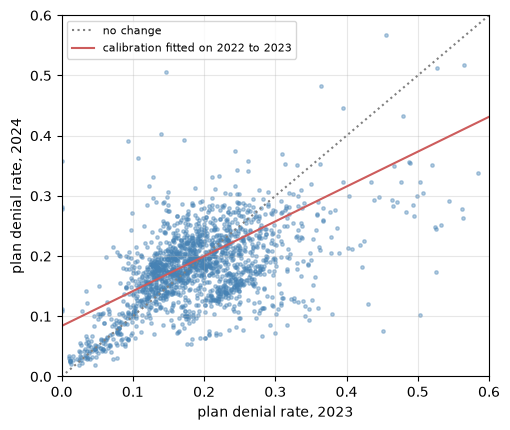

In [7]:
def pair(a, b):
    return use[a][["Plan_ID", "rate"]].merge(use[b][["Plan_ID", "rate", "iss"]], on="Plan_ID", suffixes=("_prev", "_cur"))
cal, test = pair(2022, 2023), pair(2023, 2024)
print(f"Plans observed in both 2022 and 2023: {len(cal)} | in both 2023 and 2024: {len(test)} of {len(use[2024])} usable 2024 plans")
print(f"Plan-level correlation of consecutive years: 2022-23 {cal['rate_prev'].corr(cal['rate_cur']):.3f}, 2023-24 {test['rate_prev'].corr(test['rate_cur']):.3f}")

slope, intercept = np.polyfit(cal["rate_prev"], cal["rate_cur"], 1)      # fitted on the earlier pair only
print(f"Calibration fitted on 2022 to 2023: rate_next = {intercept:.3f} + {slope:.3f} x rate_prev")

# Insurer prior rate for the test pair, and a calibration for it fitted on the earlier pair
ins_rate = {cy: use[cy].groupby("iss").apply(lambda g: g[DEN + "_num"].sum() / g[REC + "_num"].sum(), include_groups=False)
            for cy in (2022, 2023)}
cal["ins_prev"] = cal["iss"].map(ins_rate[2022]); test["ins_prev"] = test["iss"].map(ins_rate[2023])
ok = cal["ins_prev"].notna()
s2, i2 = np.polyfit(cal.loc[ok, "ins_prev"], cal.loc[ok, "rate_cur"], 1)

yt = test["rate_cur"].values
table5 = pd.Series({
    "Mean of 2023 plan rates": mean_absolute_error(yt, np.full(len(test), use[2023]["rate"].mean())),
    "Plan's 2023 rate (raw persistence)": mean_absolute_error(yt, test["rate_prev"]),
    "Insurer's 2023 rate, calibrated on 2022 to 2023": mean_absolute_error(yt[test["ins_prev"].notna()],
                                                       i2 + s2 * test.loc[test["ins_prev"].notna(), "ins_prev"]),
    "Plan's 2023 rate, calibrated on 2022 to 2023": mean_absolute_error(yt, intercept + slope * test["rate_prev"]),
    "Reference: mean of actual 2024 rates (not available in advance)": mean_absolute_error(yt, np.full(len(test), yt.mean())),
}, name="MAE on 2024 rates")
print(table5.round(4).to_string())
base5 = table5.iloc[0]
print(f"Reduction in MAE from calibrated plan persistence vs 2023 mean: {1 - table5.iloc[3] / base5:.3f}")

# Paired comparison of absolute errors, with a cluster bootstrap over insurers
err_base = np.abs(yt - use[2023]["rate"].mean()); err_cal = np.abs(yt - (intercept + slope * test["rate_prev"].values))
diff = pd.Series(err_base - err_cal).groupby(test["iss"].values)
iss_ids = test["iss"].unique(); rng = np.random.default_rng(SEED); bd = []
sums, counts = diff.sum(), diff.size()
for b in range(2000):
    pick = rng.choice(iss_ids, len(iss_ids), replace=True)
    bd.append(sums[pick].sum() / counts[pick].sum())
print(f"Mean reduction in absolute error: {np.mean(err_base - err_cal):.4f}; 95% cluster-bootstrap interval {np.percentile(bd, 2.5):.4f} to {np.percentile(bd, 97.5):.4f}")

fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.scatter(test["rate_prev"], test["rate_cur"], s=6, alpha=0.4, color="steelblue")
xs = np.linspace(0, 0.6, 50)
ax.plot(xs, xs, color="grey", ls=":", label="no change")
ax.plot(xs, intercept + slope * xs, color="indianred", label="calibration fitted on 2022 to 2023")
ax.set_xlim(0, 0.6); ax.set_ylim(0, 0.6)
ax.set_xlabel("plan denial rate, 2023"); ax.set_ylabel("plan denial rate, 2024"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG / "fig3_temporal.png", dpi=200); plt.show()